In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files
uploaded= files.upload()
file_name = next (iter(uploaded))
df = pd.read_csv(file_name)
print("dataset loaded successfully!")

Saving Nassau Candy Distributor.csv to Nassau Candy Distributor.csv
dataset loaded successfully!


In [ ]:
print("FIRST 5 ROWS:")
display(df.head())

print("\nDATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

FIRST 5 ROWS:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90



DATASET SHAPE:
(10194, 18)

COLUMN NAMES:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']


In [ ]:
print("MISSSING VALUES:")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nNEGATIVE SALES:")
print((df['Sales'] < 0).sum())

print("\nNEGATIVE COST:")
print((df['Cost'] < 0).sum())

print("\nNEGATIVE GROSS PROFIT:")
print((df['Gross Profit'] < 0).sum())

print("\nZERO UNITS:")
print((df['Units'] == 0).sum())

MISSSING VALUES:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

TOTAL MISSING VALUES:
0

DUPLICATE RECORDS:
0

DATA TYPES:
Row ID              int64
Order ID           object
Order Date         object
Ship Date          object
Ship Mode          object
Customer ID         int64
Country/Region     object
City               object
State/Province     object
Postal Code        object
Division           object
Region             object
Product ID         object
Product Name       object
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

NEGATIVE SALES:
0

NEGATIVE COST:
0

NEGATIVE GROSS PROFIT:
0

ZERO

In [ ]:
from pandas.core.arrays import numeric
df.columns = df.columns.str.strip()

df["Order Date"] = pd.to_datetime(df["Order Date"], errors='coerce')
df["Ship Date"] = pd.to_datetime(df["Ship Date"],errors='coerce')

numeric_columns=['Sales','Gross Profit','Cost','Units']

for col in numeric_columns:
  df[col] = pd.to_numeric(df[col], errors='coerce')

print("Data Cleaning Completed!")
print(df.dtypes)



Data Cleaning Completed!
Row ID                     int64
Order ID                  object
Order Date        datetime64[ns]
Ship Date         datetime64[ns]
Ship Mode                 object
Customer ID                int64
Country/Region            object
City                      object
State/Province            object
Postal Code               object
Division                  object
Region                    object
Product ID                object
Product Name              object
Sales                    float64
Units                      int64
Gross Profit             float64
Cost                     float64
dtype: object


In [ ]:
print("MISSING VALUES IN EACH COLUMN:")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

print("\nMISSING VALUE PERCENRTAGE:")
print((df.isnull().sum() / len(df))*100)

MISSING VALUES IN EACH COLUMN:
Row ID               0
Order ID             0
Order Date        6064
Ship Date            0
Ship Mode            0
Customer ID          0
Country/Region       0
City                 0
State/Province       0
Postal Code          0
Division             0
Region               0
Product ID           0
Product Name         0
Sales                0
Units                0
Gross Profit         0
Cost                 0
dtype: int64

TOTAL MISSING VALUES:
6064

MISSING VALUE PERCENRTAGE:
Row ID             0.000000
Order ID           0.000000
Order Date        59.485972
Ship Date          0.000000
Ship Mode          0.000000
Customer ID        0.000000
Country/Region     0.000000
City               0.000000
State/Province     0.000000
Postal Code        0.000000
Division           0.000000
Region             0.000000
Product ID         0.000000
Product Name       0.000000
Sales              0.000000
Units              0.000000
Gross Profit       0.000000
Cost      

In [ ]:
print("DUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nDUPLICATE ROW IDs:")
print(df['Row ID'].duplicated().sum())

print("\nNEGATIVE SALES:")
print((df['Sales'] < 0).sum())

print("\nNEGATIVE COST:")
print((df['Cost'] < 0).sum())

print("\nNEGATIVE GROSS PROFIT:")
print((df['Gross Profit'] < 0).sum())

print("\nZERO UNITS:")
print((df['Units'] == 0).sum())

DUPLICATE ROWS:
0

DUPLICATE ROW IDs:
0

NEGATIVE SALES:
0

NEGATIVE COST:
0

NEGATIVE GROSS PROFIT:
0

ZERO UNITS:
0


In [ ]:
df['Gross margin %']= (df['Gross Profit']/df['Sales'])*100
df["Profit per unit"]= df["Gross Profit"]/df["Units"]
display (df[['Product Name','Sales','Gross Profit','Cost','Units','Gross margin %','Profit per unit']].head(10))

,Product Name,Sales,Gross Profit,Cost,Units,Gross margin %,Profit per unit
0,Wonka Bar - Milk Chocolate,6.50,4.22,2.28,2,64.923077,2.11
1,Wonka Bar - Triple Dazzle Caramel,7.50,4.90,2.60,2,65.333333,2.45
2,Wonka Bar - Nutty Crunch Surprise,10.47,7.47,3.00,3,71.346705,2.49
3,Wonka Bar -Scrumdiddlyumptious,10.80,7.50,3.30,3,69.444444,2.50
4,Wonka Bar - Triple Dazzle Caramel,11.25,7.35,3.90,3,65.333333,2.45
5,Wonka Bar -Scrumdiddlyumptious,32.40,22.50,9.90,9,69.444444,2.50
6,Wonka Bar - Triple Dazzle Caramel,7.50,4.90,2.60,2,65.333333,2.45
7,Wonka Bar - Milk Chocolate,9.75,6.33,3.42,3,64.923077,2.11
8,Wonka Bar - Nutty Crunch Surprise,6.98,4.98,2.00,2,71.346705,2.49
9,Wonka Bar - Milk Chocolate,13.00,8.44,4.56,4,64.923077,2.11


In [ ]:
product_analysis = df.groupby('Product Name').agg(
    Total_Sales=('Sales','sum'),
    Total_Units=('Units', 'sum'),
    Total_Cost=('Cost', 'sum'),
    Total_Profit=('Gross Profit', 'sum')
).reset_index()

product_analysis['Gross Margin %'] = (product_analysis['Total_Profit'] / product_analysis['Total_Sales']) * 100
product_analysis['Profit per Unit'] = (product_analysis['Total_Profit'] / product_analysis['Total_Units'])
display(product_analysis.sort_values(by='Total_Sales', ascending=False))

,Product Name,Total_Sales,Total_Units,Total_Cost,Total_Profit,Gross Margin %,Profit per Unit
12,Wonka Bar - Triple Dazzle Caramel,28485.00,7596,9874.80,18610.20,65.333333,2.45
13,Wonka Bar -Scrumdiddlyumptious,27874.80,7743,8517.30,19357.50,69.444444,2.50
10,Wonka Bar - Milk Chocolate,26867.75,8267,9424.38,17443.37,64.923077,2.11
9,Wonka Bar - Fudge Mallows,24890.40,6914,8296.80,16593.60,66.666667,2.40
11,Wonka Bar - Nutty Crunch Surprise,23574.95,6755,6755.00,16819.95,71.346705,2.49
6,Lickable Wallpaper,7860.00,393,3930.00,3930.00,50.000000,10.00
4,Kazookles,1205.75,371,1113.00,92.75,7.692308,0.25
14,Wonka Gum,597.50,478,286.80,310.70,52.000000,0.65
0,Everlasting Gobstopper,130.00,13,26.00,104.00,80.000000,8.00
1,Fizzy Lifting Drinks,78.75,21,31.50,47.25,60.000000,2.25


In [ ]:
division_analysis = df.groupby('Division').agg(
    Total_Sales=('Sales','sum'),
    Total_Units=('Units', 'sum'),
    Total_Cost=('Cost', 'sum'),
    Total_Profit=('Gross Profit', 'sum')
).reset_index()

division_analysis['Gross Margin %'] = (division_analysis['Total_Profit'] / division_analysis['Total_Sales']) * 100
total_profit= division_analysis['Total_Profit'].sum()
division_analysis['Percentage of Total Profit'] = (division_analysis['Total_Profit'] / total_profit) * 100
display(division_analysis.sort_values(by='Total_Sales', ascending=False))

,Division,Total_Sales,Total_Units,Total_Cost,Total_Profit,Gross Margin %,Percentage of Total Profit
0,Chocolate,131692.90,37275,42868.28,88824.62,67.448298,95.057747
1,Other,9663.25,1242,5329.80,4333.45,44.844643,4.637543
2,Sugar,427.48,137,142.75,284.73,66.606625,0.304710


In [ ]:
# STEP 11: FACTORY MAPPING

factory_mapping = {
    'Wonka Bar - Nutty Crunch Surprise': "Lot's O' Nuts",
    'Wonka Bar - Fudge Mallows': "Lot's O' Nuts",
    'Wonka Bar -Scrumdiddlyumptious': "Lot's O' Nuts",
    'Wonka Bar - Milk Chocolate': 'Wicked Choccys',
    'Wonka Bar Triple Dazzle Caramel': 'Wicked Choccys',
    'Laffy Taffy': 'Sugar Shack',
    'SweeTARTS': 'Sugar Shack',
    'Nerds': 'Sugar Shack',
    'Fun Dip': 'Sugar Shack',
    'Fizzy Lifting Drinks': 'Sugar Shack',
    'Everlasting Gobstopper': 'Secret Factory',
    'Hair Toffee': 'The Other Factory',
    'Lickable Wallpaper': 'Secret Factory',
    'Wonka Gum': 'Secret Factory',
    'Kazookles': 'The Other Factory'
}

df['Factory'] = df['Product Name'].map(factory_mapping)

print("UNMAPPED PRODUCTS:")
print(df[df['Factory'].isnull()]['Product Name'].unique())

print("\nFACTORY-WISE PRODUCT COUNT:")
print(df.groupby('Factory')['Product Name'].nunique())

UNMAPPED PRODUCTS:
['Wonka Bar - Triple Dazzle Caramel']

FACTORY-WISE PRODUCT COUNT:
Factory
Lot's O' Nuts        3
Secret Factory       3
Sugar Shack          5
The Other Factory    2
Wicked Choccys       1
Name: Product Name, dtype: int64


In [ ]:
# FACTORY-WISE PROFITABILITY ANALYSIS

factory_analysis = df.groupby('Factory').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Gross Profit', 'sum'),
    Total_Cost=('Cost', 'sum'),
    Total_Units=('Units', 'sum')
).reset_index()

# Calculate Gross Margin
factory_analysis['Gross Margin %'] = (
    factory_analysis['Total_Profit'] /
    factory_analysis['Total_Sales']
) * 100

# Calculate Profit Contribution
factory_analysis['Profit Contribution %'] = (
    factory_analysis['Total_Profit'] /
    factory_analysis['Total_Profit'].sum()
) * 100

display(factory_analysis.sort_values(
    by='Total_Profit', ascending=False
))

,Factory,Total_Sales,Total_Profit,Total_Cost,Total_Units,Gross Margin %,Profit Contribution %
0,Lot's O' Nuts,76340.15,52771.05,23569.10,21412,69.126207,70.518798
4,Wicked Choccys,26867.75,17443.37,9424.38,8267,64.923077,23.309854
1,Secret Factory,8587.50,4344.70,4242.80,884,50.593304,5.805892
3,The Other Factory,1282.25,152.25,1130.00,388,11.873660,0.203454
2,Sugar Shack,220.98,121.23,99.75,107,54.860168,0.162002


In [ ]:
# STEP 12: BUSINESS KPIs

total_revenue = df['Sales'].sum()
total_profit = df['Gross Profit'].sum()
total_cost = df['Cost'].sum()
total_units = df['Units'].sum()

overall_margin = (total_profit / total_revenue) * 100
profit_per_unit = total_profit / total_units

print("===== NASSAU CANDY BUSINESS KPIs =====")

print("Total Revenue:", round(total_revenue, 2))
print("Total Gross Profit:", round(total_profit, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Units Sold:", total_units)
print("Overall Gross Margin:", round(overall_margin, 2), "%")
print("Overall Profit Per Unit:", round(profit_per_unit, 2))

===== NASSAU CANDY BUSINESS KPIs =====
Total Revenue: 141783.63
Total Gross Profit: 93442.8
Total Cost: 48340.83
Total Units Sold: 38654
Overall Gross Margin: 65.91 %
Overall Profit Per Unit: 2.42


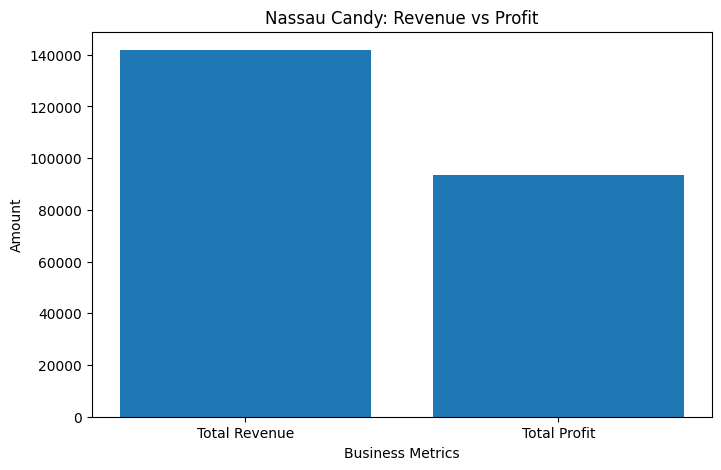

In [ ]:
# STEP 13: DATA VISUALIZATION

plt.figure(figsize=(8, 5))

metrics = ['Total Revenue', 'Total Profit']
values = [total_revenue, total_profit]

plt.bar(metrics, values)

plt.title('Nassau Candy: Revenue vs Profit')
plt.ylabel('Amount')
plt.xlabel('Business Metrics')

plt.show()

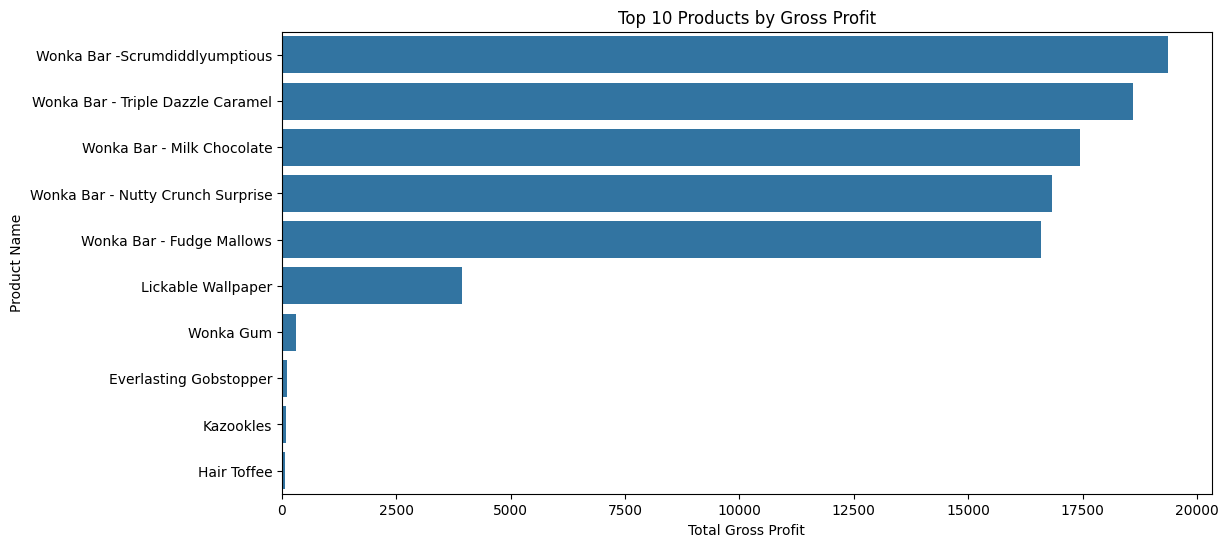

In [ ]:
# PRODUCT-WISE PROFIT CHART

top_products = product_analysis.sort_values(
    by='Total_Profit', ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x='Total_Profit',
    y='Product Name'
)

plt.title('Top 10 Products by Gross Profit')
plt.xlabel('Total Gross Profit')
plt.ylabel('Product Name')

plt.show()

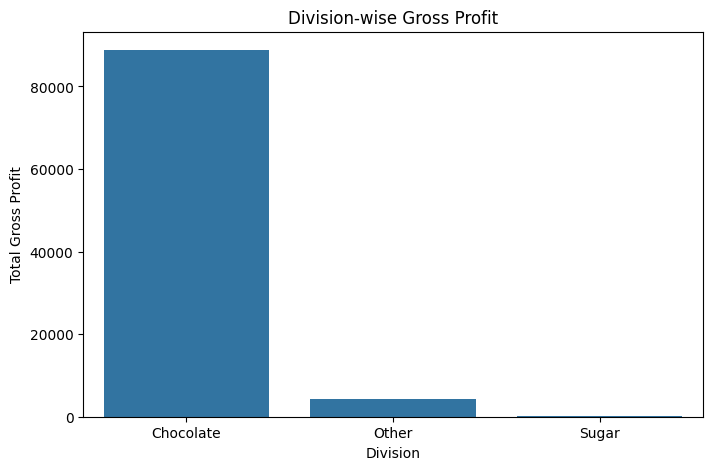

In [ ]:
# DIVISION-WISE PROFIT CHART

plt.figure(figsize=(8, 5))

sns.barplot(
    data=division_analysis,
    x='Division',
    y='Total_Profit'
)

plt.title('Division-wise Gross Profit')
plt.xlabel('Division')
plt.ylabel('Total Gross Profit')

plt.show()

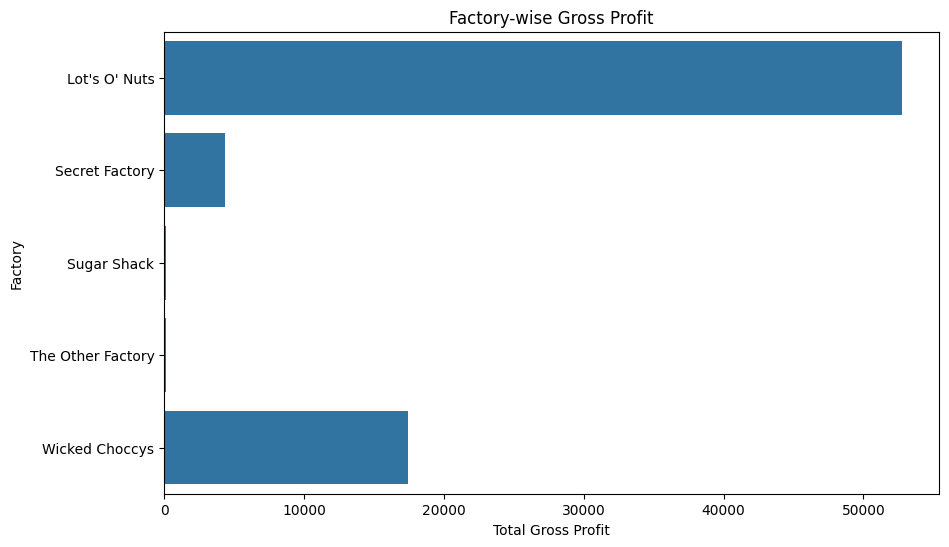

In [ ]:
# FACTORY-WISE PROFIT CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    data=factory_analysis,
    x='Total_Profit',
    y='Factory'
)

plt.title('Factory-wise Gross Profit')
plt.xlabel('Total Gross Profit')
plt.ylabel('Factory')

plt.show()

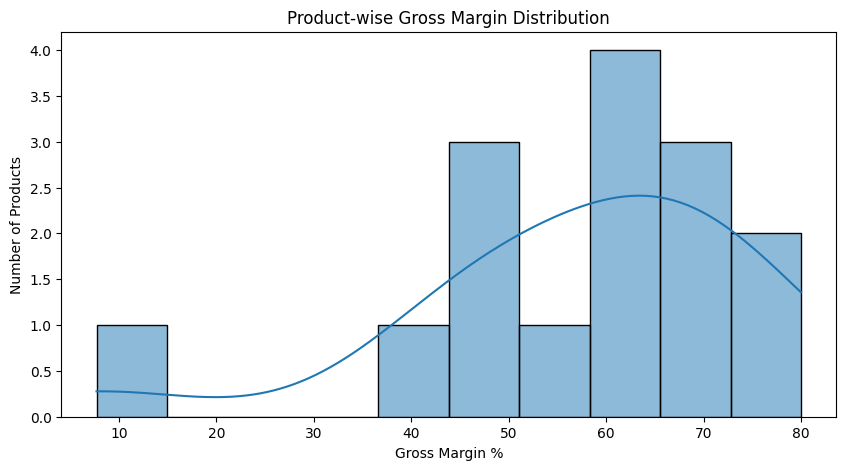

In [ ]:
# GROSS MARGIN DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=product_analysis,
    x='Gross Margin %',
    bins=10,
    kde=True
)

plt.title('Product-wise Gross Margin Distribution')
plt.xlabel('Gross Margin %')
plt.ylabel('Number of Products')

plt.show()

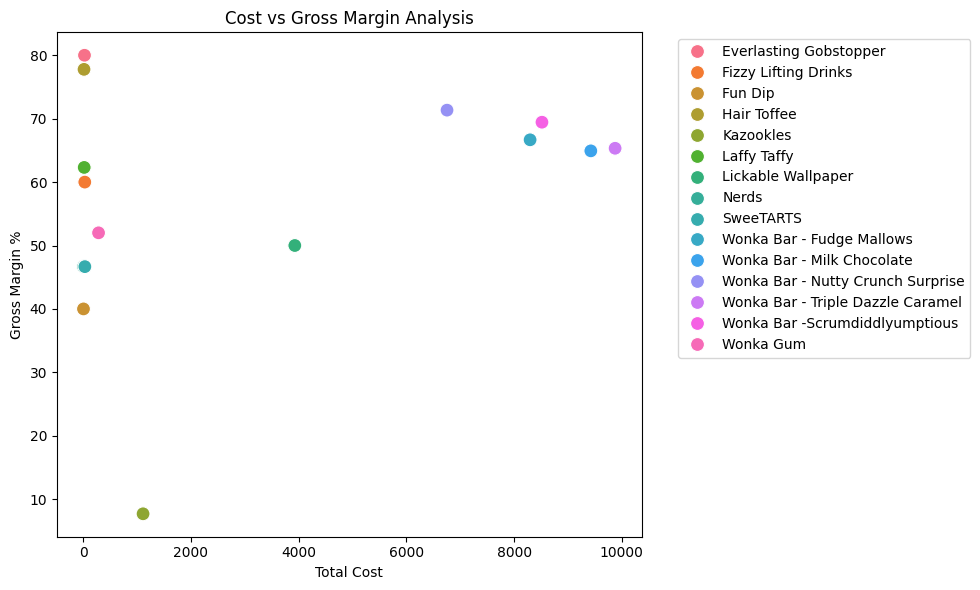

In [ ]:
# COST VS GROSS MARGIN SCATTER PLOT

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=product_analysis,
    x='Total_Cost',
    y='Gross Margin %',
    hue='Product Name',
    s=100
)

plt.title('Cost vs Gross Margin Analysis')
plt.xlabel('Total Cost')
plt.ylabel('Gross Margin %')

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

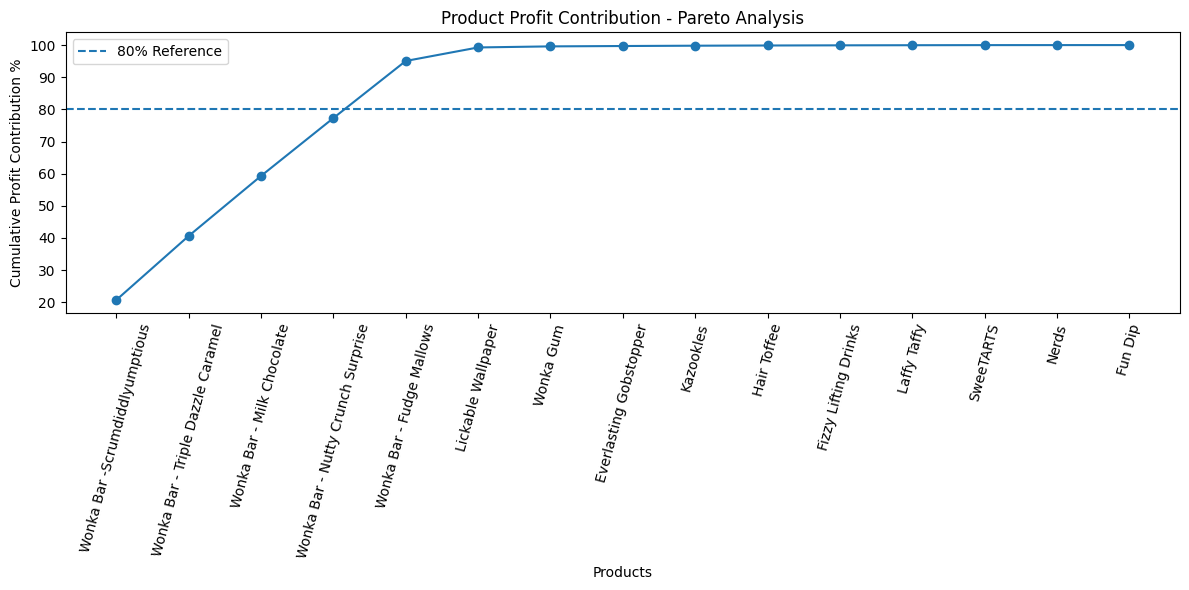

,Product Name,Total_Sales,Total_Units,Total_Cost,Total_Profit,Gross Margin %,Profit per Unit,Profit Contribution %,Cumulative Contribution %
13,Wonka Bar -Scrumdiddlyumptious,27874.80,7743,8517.30,19357.50,69.444444,2.50,20.715882,20.715882
12,Wonka Bar - Triple Dazzle Caramel,28485.00,7596,9874.80,18610.20,65.333333,2.45,19.916141,40.632023
10,Wonka Bar - Milk Chocolate,26867.75,8267,9424.38,17443.37,64.923077,2.11,18.667431,59.299454
11,Wonka Bar - Nutty Crunch Surprise,23574.95,6755,6755.00,16819.95,71.346705,2.49,18.000263,77.299717
9,Wonka Bar - Fudge Mallows,24890.40,6914,8296.80,16593.60,66.666667,2.40,17.758030,95.057747
6,Lickable Wallpaper,7860.00,393,3930.00,3930.00,50.000000,10.00,4.205782,99.263528
14,Wonka Gum,597.50,478,286.80,310.70,52.000000,0.65,0.332503,99.596031
0,Everlasting Gobstopper,130.00,13,26.00,104.00,80.000000,8.00,0.111298,99.707329
4,Kazookles,1205.75,371,1113.00,92.75,7.692308,0.25,0.099259,99.806588
3,Hair Toffee,76.50,17,17.00,59.50,77.777778,3.50,0.063675,99.870263


In [ ]:
# PARETO ANALYSIS

pareto = product_analysis.sort_values(
    by='Total_Profit', ascending=False
).copy()

pareto['Profit Contribution %'] = (
    pareto['Total_Profit'] / pareto['Total_Profit'].sum()
) * 100

pareto['Cumulative Contribution %'] = (
    pareto['Profit Contribution %'].cumsum()
)

plt.figure(figsize=(12, 6))

plt.plot(
    pareto['Product Name'],
    pareto['Cumulative Contribution %'],
    marker='o'
)

plt.axhline(y=80, linestyle='--', label='80% Reference')

plt.title('Product Profit Contribution - Pareto Analysis')
plt.xlabel('Products')
plt.ylabel('Cumulative Profit Contribution %')
plt.xticks(rotation=75)
plt.legend()
plt.tight_layout()
plt.show()

display(pareto)

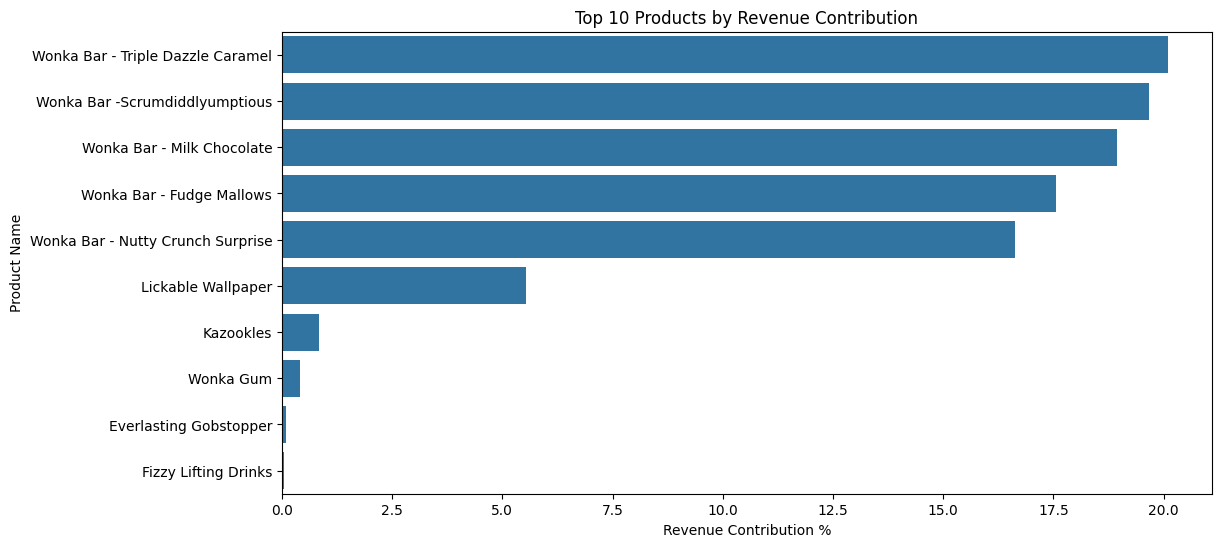

In [ ]:
# REVENUE CONTRIBUTION ANALYSIS

revenue_analysis = product_analysis.copy()

revenue_analysis['Revenue Contribution %'] = (
    revenue_analysis['Total_Sales'] /
    revenue_analysis['Total_Sales'].sum()
) * 100

revenue_analysis = revenue_analysis.sort_values(
    by='Revenue Contribution %',
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=revenue_analysis.head(10),
    x='Revenue Contribution %',
    y='Product Name'
)

plt.title('Top 10 Products by Revenue Contribution')
plt.xlabel('Revenue Contribution %')
plt.ylabel('Product Name')

plt.show()

In [ ]:
# MARGIN RISK ANALYSIS

margin_threshold = 20

product_analysis['Margin Risk'] = np.where(
    product_analysis['Gross Margin %'] < margin_threshold,
    'Low Margin Risk',
    'Healthy Margin'
)

print("MARGIN RISK SUMMARY:")
print(product_analysis['Margin Risk'].value_counts())

print("\nPRODUCTS WITH LOW MARGIN:")
display(
    product_analysis[
        product_analysis['Margin Risk'] == 'Low Margin Risk'
    ][['Product Name', 'Gross Margin %', 'Total_Profit']]
)

MARGIN RISK SUMMARY:
Margin Risk
Healthy Margin     14
Low Margin Risk     1
Name: count, dtype: int64

PRODUCTS WITH LOW MARGIN:


,Product Name,Gross Margin %,Total_Profit
4,Kazookles,7.692308,92.75


In [ ]:
# MARGIN VOLATILITY ANALYSIS

# Calculate margin volatility for each product

margin_volatility = df.groupby('Product Name')['Gross margin %'].agg(
    Average_Margin='mean',
    Margin_Volatility='std'
).reset_index()

# Sort products by highest margin volatility

margin_volatility = margin_volatility.sort_values(
    by='Margin_Volatility',
    ascending=False
)

# Display results

display(margin_volatility)

,Product Name,Average_Margin,Margin_Volatility
10,Wonka Bar - Milk Chocolate,64.923077,1.080570e-14
12,Wonka Bar - Triple Dazzle Caramel,65.333333,1.034362e-14
9,Wonka Bar - Fudge Mallows,66.666667,4.243266e-15
13,Wonka Bar -Scrumdiddlyumptious,69.444444,7.663836e-16
0,Everlasting Gobstopper,80.000000,0.000000e+00
1,Fizzy Lifting Drinks,60.000000,0.000000e+00
2,Fun Dip,40.000000,0.000000e+00
6,Lickable Wallpaper,50.000000,0.000000e+00
5,Laffy Taffy,62.311558,0.000000e+00
4,Kazookles,7.692308,0.000000e+00


In [ ]:
# FACTORY LOCATION ANALYSIS

factory_coordinates = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccys": (32.076176, -81.088371),
    "Sugar Shack": (48.119140, -96.181150),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.117500, -89.971107)
}

factory_analysis['Latitude'] = factory_analysis['Factory'].map(
    lambda x: factory_coordinates[x][0]
)

factory_analysis['Longitude'] = factory_analysis['Factory'].map(
    lambda x: factory_coordinates[x][1]
)

display(factory_analysis)

,Factory,Total_Sales,Total_Profit,Total_Cost,Total_Units,Gross Margin %,Profit Contribution %,Latitude,Longitude
0,Lot's O' Nuts,76340.15,52771.05,23569.10,21412,69.126207,70.518798,32.881893,-111.768036
1,Secret Factory,8587.50,4344.70,4242.80,884,50.593304,5.805892,41.446333,-90.565487
2,Sugar Shack,220.98,121.23,99.75,107,54.860168,0.162002,48.119140,-96.181150
3,The Other Factory,1282.25,152.25,1130.00,388,11.873660,0.203454,35.117500,-89.971107
4,Wicked Choccys,26867.75,17443.37,9424.38,8267,64.923077,23.309854,32.076176,-81.088371


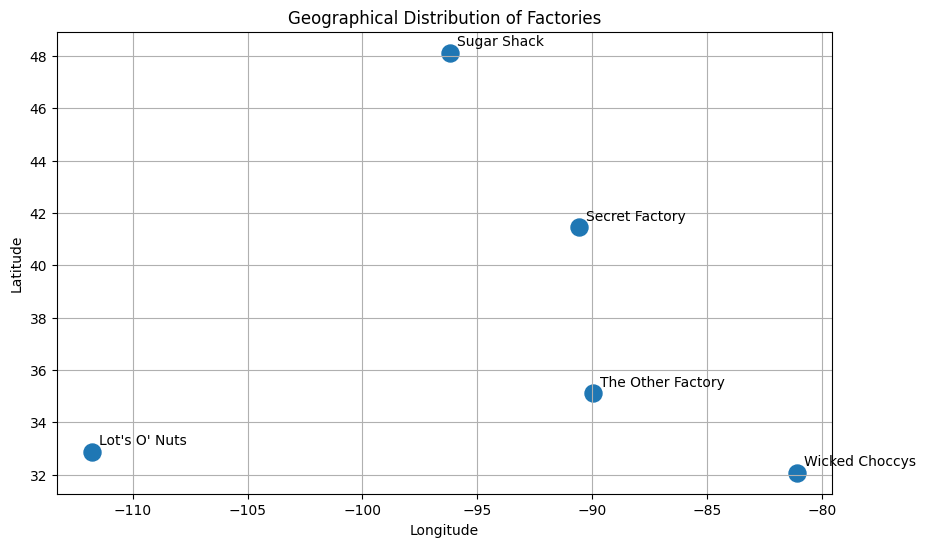

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    factory_analysis['Longitude'],
    factory_analysis['Latitude'],
    s=150
)

for _, row in factory_analysis.iterrows():
    plt.annotate(
        row['Factory'],
        (row['Longitude'], row['Latitude']),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.title('Geographical Distribution of Factories')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid()
plt.show()

In [ ]:
!pip install  streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 42.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 74.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(
    page_title="Nassau Candy Analytics",
    page_icon="🍬",
    layout="wide"
)

st.title("🍬 Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance Analysis")

st.write("Welcome to the Business Analytics Dashboard!")

st.success("Dashboard Application Started Successfully!")

Writing app.py


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(
    page_title="Nassau Candy Analytics",
    page_icon="🍬",
    layout="wide"
)

st.title("🍬 Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance Analysis")

# Load Dataset
df = pd.read_csv("Nassau_Candy.csv")

# Display Dataset
st.header("Dataset Overview")

st.write("Total Records:", len(df))
st.write("Total Columns:", len(df.columns))

st.dataframe(df.head(10))

Overwriting app.py


In [ ]:
import os
print(os.listdir())

['.config', 'Nassau Candy Distributor.csv', 'app.py', 'sample_data']


In [ ]:
print(file_name)

Nassau Candy Distributor.csv


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Nassau Candy Analytics",
    page_icon="🍬",
    layout="wide"
)

st.title("🍬 Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance Analysis")

# Load Dataset
df = pd.read_csv("Nassau Candy Distributor.csv")

# Calculate KPIs
total_revenue = df['Sales'].sum()
total_profit = df['Gross Profit'].sum()
total_cost = df['Cost'].sum()
total_units = df['Units'].sum()
gross_margin = (total_profit / total_revenue) * 100

# Dashboard KPI Cards
st.header("Business Performance Overview")

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Revenue", f"${total_revenue:,.2f}")
col2.metric("Total Profit", f"${total_profit:,.2f}")
col3.metric("Total Cost", f"${total_cost:,.2f}")
col4.metric("Gross Margin", f"{gross_margin:.2f}%")

st.metric("Total Units Sold", f"{total_units:,.0f}")

# Dataset Preview
st.header("Dataset Overview")
st.dataframe(df.head(10))

Overwriting app.py


In [ ]:
!streamlit run app.py & npx localtunnel --port 8501

⠙⠹⠸

⠼⠴⠦Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) 2026-11-03 18:52:39.210 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.194.131.19:8501

  Stopping...
^C


In [ ]:
!pip install -q  streamlit

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [ ]:
!sleep 5
!cat streamlit.log



2026-11-03 18:53:26.029 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.194.131.19:8501



In [ ]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Tue, 03 Nov 2026 18:56:10 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Tue, 03 Nov 2026 18:43:19 GMT
etag: "c27e74e6504a207997e3cd599cab079b"
cache-control: no-cache



In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼your url is: https://mighty-ghosts-ask.loca.lt
^C


In [ ]:
!cat streamlit.log



2026-11-03 18:53:26.029 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.194.131.19:8501

  Stopping...


In [ ]:
!cat app.py


import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Nassau Candy Analytics",
    page_icon="🍬",
    layout="wide"
)

st.title("🍬 Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance Analysis")

# Load Dataset
df = pd.read_csv("Nassau Candy Distributor.csv")

# Calculate KPIs
total_revenue = df['Sales'].sum()
total_profit = df['Gross Profit'].sum()
total_cost = df['Cost'].sum()
total_units = df['Units'].sum()
gross_margin = (total_profit / total_revenue) * 100

# Dashboard KPI Cards
st.header("Business Performance Overview")

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Revenue", f"${total_revenue:,.2f}")
col2.metric("Total Profit", f"${total_profit:,.2f}")
col3.metric("Total Cost", f"${total_cost:,.2f}")
col4.metric("Gross Margin", f"{gross_margin:.2f}%")

st.metric("Total Units Sold", f"{total_units:,.0f}")

# Dataset Preview
st.header("Dataset Overview")
st.dataframe(df.head(10))


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Nassau Candy Analytics",
    page_icon="🍬",
    layout="wide"
)

st.title("Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance Analysis")

df = pd.read_csv("Nassau Candy Distributor.csv")

total_revenue = df['Sales'].sum()
total_profit = df['Gross Profit'].sum()
total_cost = df['Cost'].sum()
total_units = df['Units'].sum()

gross_margin = (total_profit / total_revenue) * 100

st.header("Business Performance Overview")

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Revenue", f"${total_revenue:,.2f}")
col2.metric("Total Profit", f"${total_profit:,.2f}")
col3.metric("Total Cost", f"${total_cost:,.2f}")
col4.metric("Gross Margin", f"{gross_margin:.2f}%")

st.metric("Total Units Sold", f"{total_units:,.0f}")

st.header("Dataset Overview")
st.dataframe(df.head(10))

Writing app.py


In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 20.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://itchy-foxes-visit.loca.lt
^C


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0



2026-11-07 12:22:47.396 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.237.183.28:8501

  Stopping...


In [ ]:
!python -m streamlit run app.py --server.port 8501 --server.address 0.0.0.0



2026-11-07 13:16:50.437 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.237.183.28:8501

  Stopping...
  Stopping...


In [ ]:
!npx --yes localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://nice-moose-bathe.loca.lt
^C


In [ ]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
print ("Dashboard libraries ready!")

Dashboard libraries ready!


In [ ]:
print(df.head())
print(df.columns)

   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code   Division    Region     Product ID  \
0       77095  Chocolate  Interior  CHO-MIL-31000   
1       60540  Chocola

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Nassau Candy Distributor.csv to Nassau Candy Distributor.csv


In [ ]:
import pandas as pd
df = pd.read_csv('Nassau Candy Distributor.csv')
print(df.head())
print(df.shape)
print(df.columns)

   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code   Division    Region     Product ID  \
0       77095  Chocolate  Interior  CHO-MIL-31000   
1       60540  Chocola

In [ ]:
df.columns = df.columns.str.strip()

df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

df= df.drop_duplicates()

print("Data preparation completed!")
print(df.info())

ValueError: time data "13-01-2024" doesn't match format "%m-%d-%Y", at position 8. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
print(df['Order Date'].head())
print(df['Ship Date'].head())

0    03-01-2024
1    04-01-2024
2    04-01-2024
3    04-01-2024
4    05-01-2024
Name: Order Date, dtype: object
0    30-06-2026
1    01-07-2026
2    01-07-2026
3    01-07-2026
4    05-07-2026
Name: Ship Date, dtype: object


In [ ]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert dates (DD-MM-YYYY format)
df['Order Date'] = pd.to_datetime(
    df['Order Date'], format='%d-%m-%Y'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'], format='%d-%m-%Y'
)

# Remove duplicate records
df = df.drop_duplicates()

print("Data preparation completed!")

df.info()

Data preparation completed!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  int64         
 6   Country/Region  10194 non-null  object        
 7   City            10194 non-null  object        
 8   State/Province  10194 non-null  object        
 9   Postal Code     10194 non-null  object        
 10  Division        10194 non-null  object        
 11  Region          10194 non-null  object        
 12  Product ID      10194 non-null  object        
 13  Product Name    10194 non-null  object        
 14  Sales           10194 non-

In [3]:
total_sales = df['Sales'].sum()
total_profit = df['Gross Profit'].sum()
total_units = df['Units'].sum()
total_cost = df['Cost'].sum()

profit_margin = (total_profit / total_sales) * 100

fig = go.Figure()

fig.add_trace(go.Indicator(
    mode="number",
    value=total_sales,
    title={"text": "Total Revenue"},
    domain={'x': [0, 0.48], 'y': [0.55, 1]}
))

fig.add_trace(go.Indicator(
    mode="number",
    value=total_profit,
    title={"text": "Gross Profit"},
    domain={'x': [0.52, 1], 'y': [0.55, 1]}
))

fig.add_trace(go.Indicator(
    mode="number",
    value=total_units,
    title={"text": "Total Units Sold"},
    domain={'x': [0, 0.48], 'y': [0, 0.45]}
))

fig.add_trace(go.Indicator(
    mode="number",
    value=profit_margin,
    number={'suffix': '%'},
    title={"text": "Profit Margin"},
    domain={'x': [0.52, 1], 'y': [0, 0.45]}
))

fig.update_layout(
    title="Nassau Candy Distributor – Business Overview",
    height=550
)

fig.show()

In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('Nassau Candy Distributor.csv')

df.columns = df.columns.str.strip()

df['Order Date'] = pd.to_datetime(
    df['Order Date'], format='%d-%m-%Y'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'], format='%d-%m-%Y'
)

df = df.drop_duplicates()

print("Dataset loaded successfully!")
print(df.shape)

Saving Nassau Candy Distributor.csv to Nassau Candy Distributor.csv
Dataset loaded successfully!
(10194, 18)


In [4]:
product_profit = df.groupby('Product Name')['Gross Profit'].sum().reset_index()

product_profit = product_profit.sort_values(
    by='Gross Profit', ascending=False
)

fig = px.bar(
    product_profit,
    x='Product Name',
    y='Gross Profit',
    title='Product-wise Gross Profit Analysis',
    color='Gross Profit',
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='Product Name',
    yaxis_title='Gross Profit',
    xaxis_tickangle=-45,
    height=600
)

fig.show()

In [5]:
region_sales = df.groupby('Region')['Sales'].sum().reset_index()

fig = px.pie(
    region_sales,
    names='Region',
    values='Sales',
    title='Region-wise Sales Distribution',
    hole=0.4,
    template='plotly_white'
)

fig.update_traces(
    textinfo='label+percent',
    textposition='inside'
)

fig.update_layout(height=550)

fig.show()

In [6]:
df['Month'] = df['Order Date'].dt.to_period('M').astype(str)

monthly_sales = df.groupby('Month')['Sales'].sum().reset_index()

fig = px.line(
    monthly_sales,
    x='Month',
    y='Sales',
    title='Monthly Revenue Trend',
    markers=True,
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='Month',
    yaxis_title='Total Revenue',
    height=500
)

fig.show()

In [7]:
division_profit = df.groupby('Division')['Gross Profit'].sum().reset_index()

fig = px.bar(
    division_profit,
    x='Division',
    y='Gross Profit',
    title='Division-wise Gross Profit Analysis',
    color='Division',
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='Division',
    yaxis_title='Gross Profit',
    height=500
)

fig.show()

In [8]:
cost_revenue = df.groupby('Region')[['Sales', 'Cost']].sum().reset_index()

fig = px.bar(
    cost_revenue,
    x='Region',
    y=['Sales', 'Cost'],
    barmode='group',
    title='Revenue vs Cost by Region',
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='Region',
    yaxis_title='Amount',
    height=550
)

fig.show()

In [9]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Prepare data
top_products = product_profit.head(10)

fig = make_subplots(
    rows=3, cols=2,
    subplot_titles=(
        "Top 10 Products by Profit",
        "Regional Sales Distribution",
        "Monthly Revenue Trend",
        "Division-wise Profit",
        "Revenue vs Cost by Region"
    ),
    specs=[
        [{"type": "bar"}, {"type": "domain"}],
        [{"type": "scatter"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "bar"}]
    ],
    vertical_spacing=0.12
)

# Product profitability
fig.add_trace(
    go.Bar(
        x=top_products['Gross Profit'],
        y=top_products['Product Name'],
        orientation='h',
        name='Gross Profit'
    ), row=1, col=1
)

# Regional sales
fig.add_trace(
    go.Pie(
        labels=region_sales['Region'],
        values=region_sales['Sales'],
        hole=0.4
    ), row=1, col=2
)

# Monthly revenue
fig.add_trace(
    go.Scatter(
        x=monthly_sales['Month'],
        y=monthly_sales['Sales'],
        mode='lines+markers',
        name='Monthly Revenue'
    ), row=2, col=1
)

# Division profit
fig.add_trace(
    go.Bar(
        x=division_profit['Division'],
        y=division_profit['Gross Profit'],
        name='Division Profit'
    ), row=2, col=2
)

# Revenue vs cost
fig.add_trace(
    go.Bar(
        x=cost_revenue['Region'],
        y=cost_revenue['Sales'],
        name='Revenue'
    ), row=3, col=1
)

fig.add_trace(
    go.Bar(
        x=cost_revenue['Region'],
        y=cost_revenue['Cost'],
        name='Cost'
    ), row=3, col=2
)

fig.update_layout(
    title='NASSAU CANDY DISTRIBUTOR – BUSINESS PERFORMANCE DASHBOARD',
    height=1200,
    template='plotly_white',
    showlegend=True
)

fig.show()

In [10]:
fig.write_html(
    "Nassau_Candy_Dashboard.html",
    include_plotlyjs=True
)

print("Dashboard exported successfully!")

Dashboard exported successfully!


In [11]:
from google.colab import files

files.download("Nassau_Candy_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>